# Random forest

Trains a `RandomForestRegressor` on the shared `pnw_model_dataset.csv` and scores it against the climatology baseline.

In [1]:
# 1. Setup
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

SEED = 16

In [2]:
# 2. Load the data
csv_path = "../datacleaning-pipeline/pnw_model_dataset.csv"
df = pd.read_csv(csv_path, dtype={"gauge_id": str}, parse_dates=["date"])

print(df.shape)
print(df["split"].value_counts())

(269534, 28)
train     149732
test       89872
warmup     29930
Name: split, dtype: int64


In [3]:
# 3. Inputs & target
# Raw columns, not the `_z` ones: a tree splits on thresholds, so scaling changes nothing, and raw units keep the importance chart readable.
input_cols = [
    "prcp", "tmax", "srad", "vp", "dayl",
    "drainage_area_km2", "elevation_m", "slope_m_per_km", "frac_forest",
    "mean_precip_mm_day", "mean_pet_mm_day",
]
target_col = "log_runoff"

In [4]:
# 4. Split
# Train = Oct 2006 – Sep 2011, test = Oct 2011 – Sep 2014, from the `split` column. Warm-up rows are not used; they exist for the LSTM.
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

X_train, y_train = train[input_cols], train[target_col]
X_test, y_test = test[input_cols], test[target_col]

print(len(X_train), "train rows,", len(X_test), "test rows")

149732 train rows, 89872 test rows


In [5]:
# 5. Baseline
# Climatology: for each basin and calendar day, the mean runoff over the training years. Keyed on month-day so leap years do not shift the calendar.
train_mmdd = train["date"].dt.strftime("%m-%d")
test_mmdd = test["date"].dt.strftime("%m-%d")

climatology = (
    train.assign(mmdd=train_mmdd)
    .groupby(["gauge_id", "mmdd"])["runoff_mm_day"]
    .mean()
    .rename("baseline_runoff")
)

test = test.assign(mmdd=test_mmdd).join(climatology, on=["gauge_id", "mmdd"])
print(test["baseline_runoff"].isna().sum(), "test rows with no baseline (should be 0)")

0 test rows with no baseline (should be 0)


In [6]:
# 6. Train
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=SEED,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

# Settings: 200 trees, unlimited depth, seed 16, all other scikit-learn defaults. 200 trees follows Shanko & Melesse (2026).


RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=16)

In [7]:
# 7. Predict
# Undo the log with `np.expm1`; clip at zero so all three models treat negative predictions the same way.
pred_log = rf.predict(X_test)
test = test.assign(
    pred_runoff=np.clip(np.expm1(pred_log), a_min=0.0, a_max=None),
    obs_runoff=test["runoff_mm_day"],
)

print(test[["obs_runoff", "pred_runoff", "baseline_runoff"]].describe().round(2))

       obs_runoff  pred_runoff  baseline_runoff
count    89872.00     89872.00         89872.00
mean         4.46         3.83             4.46
std          6.57         4.61             4.95
min          0.00         0.00             0.00
25%          0.63         0.71             0.74
50%          2.13         2.28             2.76
75%          5.85         5.59             6.78
max        149.21        99.96            95.97


In [8]:
# 8. Scores
# NSE and RMSE on the original scale (mm/day), pooled and per-basin median. High-flow day = runoff above the basin's 95th percentile over the training years.
def nse(obs, pred):
    return 1 - np.sum((obs - pred) ** 2) / np.sum((obs - obs.mean()) ** 2)

def rmse(obs, pred):
    return np.sqrt(np.mean((obs - pred) ** 2))

cutoff = train.groupby("gauge_id")["runoff_mm_day"].quantile(0.95).rename("cutoff")
test = test.join(cutoff, on="gauge_id")
test["obs_high"] = test["obs_runoff"] > test["cutoff"]

def score(pred_col):
    obs, pred = test["obs_runoff"], test[pred_col]
    per_basin = test.groupby("gauge_id").apply(lambda g: nse(g["obs_runoff"], g[pred_col]))
    pred_high = pred > test["cutoff"]
    return {
        "NSE pooled": nse(obs, pred),
        "NSE per-basin median": per_basin.median(),
        "RMSE mm/day": rmse(obs, pred),
        "high-flow recall": (pred_high & test["obs_high"]).sum() / test["obs_high"].sum(),
        "high-flow precision": (pred_high & test["obs_high"]).sum() / max(pred_high.sum(), 1),
    }

results = pd.DataFrame({
    "random forest": score("pred_runoff"),
    "climatology": score("baseline_runoff"),
}).round(3)
results

,random forest,climatology
NSE pooled,0.569,0.168
NSE per-basin median,0.495,0.073
RMSE mm/day,4.311,5.992
high-flow recall,0.206,0.070
high-flow precision,0.585,0.160


mean_precip_mm_day    0.278
tmax                  0.219
dayl                  0.148
prcp                  0.084
srad                  0.075
elevation_m           0.060
vp                    0.049
slope_m_per_km        0.038
mean_pet_mm_day       0.023
drainage_area_km2     0.014
frac_forest           0.013
dtype: float64


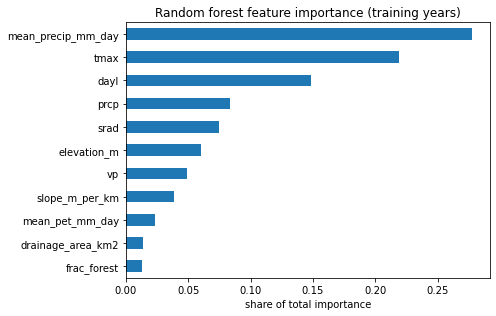

In [11]:
# 9. Importance
# Share of variance reduction each input contributed across all 200 trees; sums to 1.
# Correlation, not causation; credit is shared between correlated inputs.
import matplotlib.pyplot as plt

importance = (
    pd.Series(rf.feature_importances_, index=input_cols)
    .sort_values(ascending=True)
)
print(importance.round(3).sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
importance.plot.barh(ax=ax)
ax.set_xlabel("share of total importance")
ax.set_title("Random forest feature importance (training years)")
plt.tight_layout()
plt.show()



basin 12189500 NSE 0.49


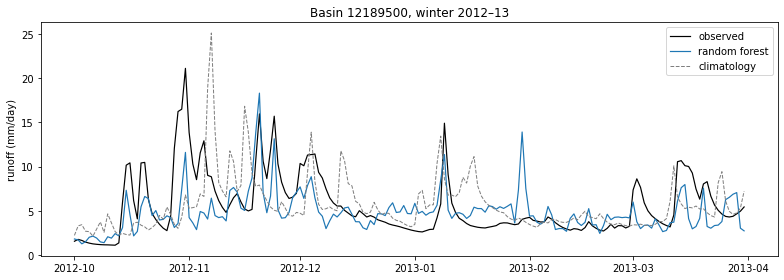

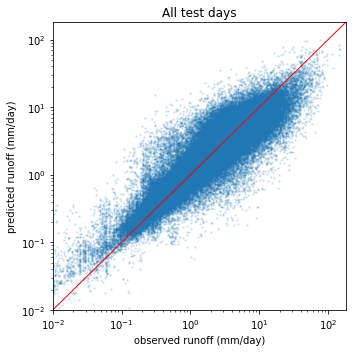

In [14]:
# 10. Plots
# One typical basin (NSE closest to the median) over one winter, plus observed vs predicted for every test day.
per_basin = test.groupby("gauge_id").apply(lambda g: nse(g["obs_runoff"], g["pred_runoff"]))
typical = (per_basin - per_basin.median()).abs().idxmin()
print("basin", typical, "NSE", round(per_basin[typical], 3))

one = test[(test["gauge_id"] == typical) & (test["date"] >= "2012-10-01") & (test["date"] <
"2013-04-01")]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(one["date"], one["obs_runoff"], label="observed", color="black", lw=1.2)
ax.plot(one["date"], one["pred_runoff"], label="random forest", color="tab:blue", lw=1.2)
ax.plot(one["date"], one["baseline_runoff"], label="climatology", color="tab:gray", lw=1, ls="--")
ax.set_ylabel("runoff (mm/day)")
ax.set_title(f"Basin {typical}, winter 2012–13")
ax.legend()
plt.tight_layout()
plt.show()

pos = test[(test["obs_runoff"] > 0) & (test["pred_runoff"] > 0)]
lo, hi = 0.01, pos["obs_runoff"].max() * 1.2

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(pos["obs_runoff"], pos["pred_runoff"], s=2, alpha=0.15)
ax.plot([lo, hi], [lo, hi], color="red", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("observed runoff (mm/day)"); ax.set_ylabel("predicted runoff (mm/day)")
ax.set_title("All test days")
plt.tight_layout()
plt.show()

## Summary

Random forest, 200 trees, unlimited depth, seed 16, 11 raw inputs, target log(1 + runoff). Scored on the test years Oct 2011 – Sep 2014, 82 basins, original scale.

| | Random forest | Climatology |
|---|---|---|
| NSE pooled | 0.569 | 0.168 |
| NSE per-basin median | 0.495 | 0.073 |
| RMSE (mm/day) | 4.31 | 5.99 |
| High-flow recall | 0.206 | 0.070 |
| High-flow precision | 0.585 | 0.160 |

The forest beats the climatology floor by a wide margin and tracks ordinary days well (25th–75th percentiles match the observations), but it compresses the extremes: mean prediction 14 % low, maximum 100 mm/day against an observed 149, and only one high-flow day in five is caught. Feature importance puts long-run basin wetness (0.28), tmax (0.22) and day length (0.15) ahead of today's rain (0.08): with no memory, the forest leans on climate and season as stand-ins for the water that fell in previous days. The hydrograph shows the same thing: storm timing is right, peaks are clipped, and the predicted line drops the day after a storm instead of receding slowly. This is the expected weakness of a memoryless model and the gap the LSTM is meant to close; adding rolling rain totals (7- and 30-day) is the obvious next step for the forest.